# 05 · 自研函数 vs 开源库（shap / captum / torch）对比

前四个笔记本用到的**可解释性、鲁棒性、隐私性**算法都是本项目在 `py/trustoran/` 里用纯 numpy/sklearn **手写**的（KernelSHAP、LIME、有限差分 FGSM/PGD/DeepFool、DP-SGD、FedAvg、成员推断）。本笔记本把它们和业界开源实现放在**同一个模型、同一份数据**上做正面对比，回答三个问题：

| 维度 | 具体指标 |
|---|---|
| **用法方便程度** | API 复杂度、依赖体量、需要多少胶水代码 |
| **计算耗时** | 相同采样预算 / 相同 ε 下的墙钟时间 |
| **计算效果** | 归因一致性（余弦、符号一致率）、攻击翻转率与扰动范数、DP 效用 |

对比对象：
* **可解释性** — 我们的 `EX.shap_explain` / `EX.local_explanation` ↔ `shap.KernelExplainer` ↔ `captum.attr.{KernelShap, Lime, IntegratedGradients}`
* **鲁棒性** — 我们的有限差分 `RB.fgsm/pgd/deepfool` ↔ `captum.robust.{FGSM, PGD}` ↔ torch 自动求导 DeepFool（captum 无 DeepFool）
* **隐私性** — 我们的 numpy `PR.dp_train_classification` ↔ `torch.func.vmap` 实现的 DP-SGD

> **公平性原则**：为了把差异**只**归因于「梯度/归因估计方式」而不是「模型不同」，凡是能和 captum/torch 对比的地方，我们都让**双方作用在同一个 torch MLP 上**——我们的方法通过一个 `predict_proba` 包装器接入。数学推导见 `py/MATH_PRINCIPLES.md`。

In [1]:
# --- bootstrap：让 trustoran 可导入；KMP_DUPLICATE_LIB_OK 必须在 import torch 之前 ---
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # Anaconda(MKL) 与 torch 的 OpenMP 运行库冲突
import sys, pathlib, time, warnings
warnings.filterwarnings("ignore")

REPO = pathlib.Path.cwd().resolve()
while not (REPO / "py" / "trustoran").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "py"))

%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch

from trustoran.data import build_dataset, train_test_split_dataset
from trustoran.models import make_model
from trustoran.data.base import TaskType
from trustoran.trust import explainability as EX, robustness as RB, privacy as PR

import shap
import captum
from captum.attr import KernelShap, Lime, IntegratedGradients
from captum.robust import FGSM as C_FGSM, PGD as C_PGD

print("torch  ", torch.__version__)
print("shap   ", shap.__version__)
print("captum ", captum.__version__)
print("repo   ", REPO)

torch   2.14.1+cpu
shap    0.53.0
captum  0.9.0
repo    E:\可信AI


## 1 · 数据与「共享模型」

用 `cci_a1sd_binary`（A1 接口 Normal vs DoS，10 维特征）。

* **sklearn 随机森林** —— 我们和 `shap.KernelExplainer` 的**原生**对比对象（都是黑盒 `predict_proba`，无梯度）。
* **一个 torch MLP** —— captum/torch 需要自动求导，所以它就是三方（我们 / captum / torch）共用的**同一个模型**。我们用一个薄包装器 `_TorchEst` 把它伪装成 sklearn 风格估计器，好让我们的 numpy 函数能直接作用其上。

MLP **故意训练得「不饱和」**（`label_smoothing=0.1`、40 轮）：若训练到 100% 置信，softmax 概率趋近 0/1，有限差分梯度会消失，DeepFool 这类依赖梯度范数的方法会数值爆炸——这本身也是有限差分法的一个真实局限，我们在第 4 节会点明。

In [2]:
SEED = 42
ds = build_dataset("cci_a1sd_binary", max_rows=1500, seed=SEED)
sp = train_test_split_dataset(ds, test_size=0.3, seed=SEED)
Xtr, ytr = sp.X_train[:800], sp.y_train[:800]
Xte, yte = sp.X_test[:400], sp.y_test[:400]
d = Xtr.shape[1]
BG = Xtr[:40]                     # 背景集（SHAP/LIME 的边际化基准）
print("train", Xtr.shape, "test", Xte.shape, "classes", sp.train.class_names)

# ---- sklearn 随机森林：ours 与 shap.KernelExplainer 的原生对比对象 -----------
rf = make_model("random_forest", sp.train.task, sp.feature_names,
                sp.train.class_names, params={"n_estimators": 60, "n_jobs": 1})
rf.fit(Xtr, ytr)

# ---- 共享 torch MLP（不饱和）------------------------------------------------
torch.manual_seed(0)
mlp = torch.nn.Sequential(torch.nn.Linear(d, 32), torch.nn.ReLU(),
                          torch.nn.Linear(32, 2))
_Xt = torch.tensor(Xtr, dtype=torch.float32)
_yt = torch.tensor(ytr, dtype=torch.long)
_opt = torch.optim.Adam(mlp.parameters(), lr=5e-3)
_lf = torch.nn.CrossEntropyLoss(label_smoothing=0.1)
for _ in range(40):
    _opt.zero_grad(); _lf(mlp(_Xt), _yt).backward(); _opt.step()
mlp.eval()
with torch.no_grad():
    _p = torch.softmax(mlp(torch.tensor(Xte, dtype=torch.float32)), 1).numpy()
print(f"shared MLP  test-acc={(_p.argmax(1)==yte).mean():.3f}  mean-max-prob={_p.max(1).mean():.3f}")

# ---- 把 torch MLP 包装成 sklearn 风格，供我们的 numpy 函数使用 --------------
class _TorchEst:
    def __init__(self, m): self.m = m
    def predict_proba(self, X):
        with torch.no_grad():
            return torch.softmax(self.m(torch.tensor(np.asarray(X, float),
                                   dtype=torch.float32)), 1).numpy()
    def predict(self, X): return self.predict_proba(X).argmax(1)

class _WrappedTM:
    # 最小 TrustModel 替身：我们的 EX/RB 只用到 .estimator/.feature_names/.task
    def __init__(self, m, names):
        self.estimator = _TorchEst(m); self.feature_names = list(names)
        self.task = TaskType.BINARY
    def predict(self, X): return self.estimator.predict(X)
    def clone_unfitted(self): raise NotImplementedError
    def native_importance(self): return None

tm_mlp = _WrappedTM(mlp, sp.feature_names)
FEATS = list(sp.feature_names)

train (800, 10) test (400, 10) classes ['Normal', 'Dos']


shared MLP  test-acc=0.985  mean-max-prob=0.955


## 2 · 可解释性对比

三方都解释**同一个目标**：$f(x)=P(\text{class}=1)$。为公平起见，KernelSHAP 类方法统一采样预算 `n=48`（正是我们 `n_coalitions=min(2^d, max(2d+8,48))` 在 d=10 时的取值），IntegratedGradients 用 32 步积分。

**用法对比**：
* `shap.KernelExplainer(f, background)` —— 传入任意 `f` 与背景集，`shap_values(X)` 一步到位；生态最成熟，但会拉起 numba/llvmlite，**首次 import 就要几秒**，依赖体量最大。
* `captum.attr.KernelShap(forward)` —— forward 必须是**接收/返回 torch 张量**的函数，输入输出都得在 torch 张量与 numpy 间来回转换。
* 我们的 `EX.shap_explain(model, X, background, target_class=1)` —— 直接吃 sklearn 风格模型，返回带 `feature_names` 的 `ShapResult` 数据类，**零 torch 依赖**。

In [3]:
def timeit(fn, *a, **k):
    t = time.perf_counter(); out = fn(*a, **k); return out, time.perf_counter() - t

Xexp = Xte[:5]
NS = 48   # 统一采样预算

# ---- 我们的 KernelSHAP（作用在共享 MLP 上，便于与 captum 直接比一致性）----
ours_shap, t_ours_shap = timeit(EX.shap_explain, tm_mlp, Xexp, BG, target_class=1, seed=SEED)
V_ours = np.asarray(ours_shap.shap_values)

# ---- captum.attr.KernelShap（同一个 MLP）--------------------------------
_fwd = lambda z: torch.softmax(mlp(z), 1)[:, 1:2]
_xt = torch.tensor(Xexp, dtype=torch.float32)
_base = torch.tensor(BG.mean(0), dtype=torch.float32).unsqueeze(0)
cap_shap, t_cap_shap = timeit(lambda: KernelShap(_fwd).attribute(_xt, baselines=_base, n_samples=NS).detach().numpy())

# ---- captum.attr.IntegratedGradients（同一个 MLP，精确梯度路径积分）------
_ig = IntegratedGradients(_fwd)
cap_ig, t_cap_ig = timeit(lambda: _ig.attribute(_xt.clone().requires_grad_(True),
                                                baselines=_base, n_steps=32).detach().numpy())

# ---- captum.attr.Lime ------------------------------------------------------
cap_lime, t_cap_lime = timeit(lambda: Lime(_fwd).attribute(_xt, baselines=_base, n_samples=NS).detach().numpy())

# ---- 我们的 LIME 式局部代理（同一个 MLP）--------------------------------
ours_lime, t_ours_lime = timeit(EX.local_explanation, tm_mlp, Xexp[0], BG,
                                target_class=1, n_samples=200, seed=SEED)

# ---- shap.KernelExplainer 作用在 sklearn RF 上（原生黑盒用法）-----------
_f_rf = lambda Z: rf.estimator.predict_proba(np.asarray(Z, float))[:, 1]
shap_exp, t_shap_exp = timeit(lambda: shap.KernelExplainer(_f_rf, BG))
shap_vals, t_shap_vals = timeit(lambda: np.asarray(shap_exp.shap_values(Xexp, nsamples=NS, silent=True)))
t_shap_total = t_shap_exp + t_shap_vals

# ---- 我们的 KernelSHAP 作用在同一个 RF 上（苹果对苹果的耗时）-----------
ours_shap_rf, t_ours_shap_rf = timeit(EX.shap_explain, rf, Xexp, BG, target_class=1, seed=SEED)

rows = [
    ("ours  EX.shap_explain (MLP)",      t_ours_shap,     "numpy KernelSHAP"),
    ("captum KernelShap (MLP)",          t_cap_shap,      "torch, needs tensor IO"),
    ("captum IntegratedGradients (MLP)", t_cap_ig,        "torch autograd"),
    ("captum Lime (MLP)",                t_cap_lime,      "torch"),
    ("ours  EX.local_explanation (MLP)", t_ours_lime,     "numpy Ridge surrogate"),
    ("shap.KernelExplainer (RF)",        t_shap_total,    "mature, heavy deps"),
    ("ours  EX.shap_explain (RF)",       t_ours_shap_rf,  "numpy KernelSHAP"),
]
pd.DataFrame(rows, columns=["method", "time_s", "backend"]).round(4)

,method,time_s,backend
0,ours EX.shap_explain (MLP),0.0041,numpy KernelSHAP
1,captum KernelShap (MLP),0.0486,"torch, needs tensor IO"
2,captum IntegratedGradients (MLP),0.0030,torch autograd
3,captum Lime (MLP),0.0449,torch
4,ours EX.local_explanation (MLP),0.0024,numpy Ridge surrogate
5,shap.KernelExplainer (RF),0.0294,"mature, heavy deps"
6,ours EX.shap_explain (RF),0.0150,numpy KernelSHAP


### 2.1 · 归因**效果**一致性

同一个 MLP、同一个目标函数，比较我们与 captum KernelShap 的归因向量：**逐样本余弦相似度**、**符号一致率**，以及双方选出的 **Top-3 重要特征**。

> 一致性用**较高的共享预算 n=200**（两种实现都随采样数增加而收敛，对双方公平）；上一格的耗时表用 n=48 是为了对齐我们的默认预算。若三种独立实现给出高度一致的重要特征排序，就说明手写实现是正确的。

逐样本余弦相似度 (ours vs captum KernelShap, n=200): [0.825 0.719 0.975 0.828 0.483]
平均余弦 = 0.766   符号一致率 = 0.800
Top-3 特征  ours   : ['request_rate', 'response_time_mean', 'payload_size_mean']
Top-3 特征  captum : ['request_rate', 'response_time_mean', 'payload_size_mean']
Top-3 特征  captum-IG: ['request_rate', 'response_time_mean', 'payload_size_mean']


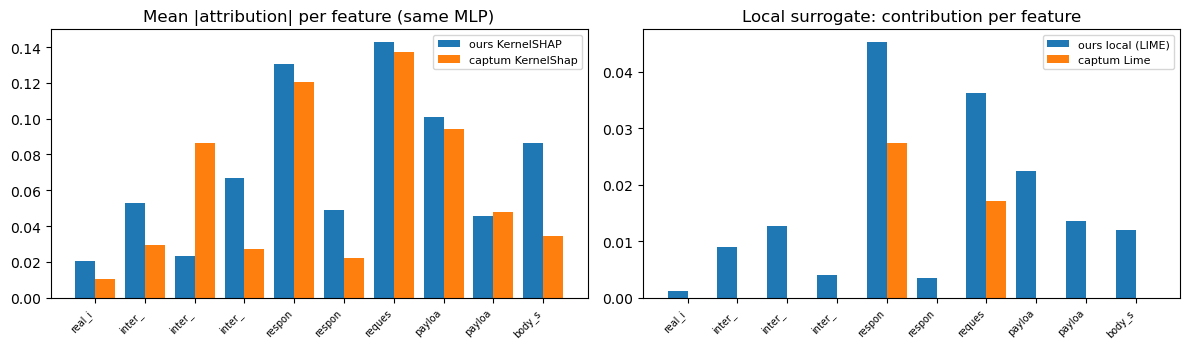

In [4]:
def _cos(a, b): return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

# 高预算一致性对比（对双方公平）
NA = 200
ours_hi = np.asarray(EX.shap_explain(tm_mlp, Xexp, BG, target_class=1,
                                     n_coalitions=NA, seed=SEED).shap_values)
cap_hi = KernelShap(_fwd).attribute(_xt, baselines=_base, n_samples=NA).detach().numpy()

cos_rows = [_cos(ours_hi[i], cap_hi[i]) for i in range(len(ours_hi))]
sign_agree = float((np.sign(ours_hi) == np.sign(cap_hi)).mean())
top_ours = np.argsort(-np.abs(ours_hi).mean(0))[:3]
top_cap  = np.argsort(-np.abs(cap_hi).mean(0))[:3]
top_ig   = np.argsort(-np.abs(cap_ig).mean(0))[:3]

print(f"逐样本余弦相似度 (ours vs captum KernelShap, n={NA}): {np.round(cos_rows,3)}")
print(f"平均余弦 = {np.mean(cos_rows):.3f}   符号一致率 = {sign_agree:.3f}")
print(f"Top-3 特征  ours   : {[FEATS[i] for i in top_ours]}")
print(f"Top-3 特征  captum : {[FEATS[i] for i in top_cap]}")
print(f"Top-3 特征  captum-IG: {[FEATS[i] for i in top_ig]}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
idx = np.arange(d)
w = 0.4
ax[0].bar(idx - w/2, np.abs(ours_hi).mean(0), w, label="ours KernelSHAP")
ax[0].bar(idx + w/2, np.abs(cap_hi).mean(0), w, label="captum KernelShap")
ax[0].set_title("Mean |attribution| per feature (same MLP)"); ax[0].legend(fontsize=8)
ax[0].set_xticks(idx); ax[0].set_xticklabels([f[:6] for f in FEATS], rotation=45, ha="right", fontsize=7)
ax[1].bar(idx - w/2, np.abs(np.asarray(ours_lime.coefficients)), w, label="ours local (LIME)")
ax[1].bar(idx + w/2, np.abs(cap_lime[0]), w, label="captum Lime")
ax[1].set_title("Local surrogate: contribution per feature"); ax[1].legend(fontsize=8)
ax[1].set_xticks(idx); ax[1].set_xticklabels([f[:6] for f in FEATS], rotation=45, ha="right", fontsize=7)
fig.tight_layout(); plt.show()

## 3 · 鲁棒性对比（FGSM / PGD / DeepFool）

三方仍作用在**同一个 MLP** 上：
* **captum.robust** 用自动求导拿**精确梯度**；
* **我们**用**中心有限差分**（`h=2e-3`）估梯度——好处是**不需要模型可微**，随机森林、SVC、任意黑盒都能攻；代价是每步要 `2·d` 次前向、且梯度有 $O(h^2)$ 误差。

指标：**翻转率**（攻击成功率）、**平均扰动范数**、**耗时**。FGSM/PGD 的扰动被 $L_\infty$ 半径 `eps` 约束，所以范数由 eps 决定；DeepFool 追求**最小**翻转扰动，范数越小说明越接近最优。

In [5]:
EPS = 0.3
logits = lambda z: mlp(z)
_xall = torch.tensor(Xte, dtype=torch.float32)
_xtg = _xall.clone().requires_grad_(True)
_tgt = torch.tensor(yte, dtype=torch.long)

def flip_np(pred, y=yte): return float((np.asarray(pred) != y).mean())

# ---- captum FGSM / PGD（精确梯度）----
cap_fgsm, t_cap_fgsm = timeit(lambda: C_FGSM(logits).perturb(_xtg, EPS, _tgt))
cap_pgd,  t_cap_pgd  = timeit(lambda: C_PGD(logits).perturb(_xtg, EPS, 0.05, 12, _tgt))
with torch.no_grad():
    flip_cap_fgsm = flip_np(mlp(cap_fgsm).argmax(1).numpy())
    flip_cap_pgd  = flip_np(mlp(cap_pgd).argmax(1).numpy())

# ---- 我们的有限差分 FGSM / PGD（同一个 MLP）----
ours_fgsm_ar, t_ours_fgsm = timeit(RB.evaluate_attack, tm_mlp, Xte, yte, "fgsm", EPS, sp.train.class_names)
ours_pgd_ar,  t_ours_pgd  = timeit(RB.evaluate_attack, tm_mlp, Xte, yte, "pgd", EPS, sp.train.class_names)
flip_ours_fgsm = ours_fgsm_ar.attack_success_rate
flip_ours_pgd  = ours_pgd_ar.attack_success_rate

# ---- DeepFool：ours(有限差分) vs torch(自动求导参考实现，captum 无此攻击) ----
def torch_deepfool(mm, X, max_iter=50, overshoot=1.02, K=2):
    x = torch.tensor(X, dtype=torch.float32); n = len(x)
    lab = mm(x).argmax(1); out = x.clone()
    for i in range(n):
        xi = x[i].clone().detach(); li = int(lab[i])
        for _ in range(max_iter):
            xi.requires_grad_(True); s = mm(xi.unsqueeze(0))[0]
            if int(s.argmax()) != li: break
            wb, fb = None, np.inf
            for k in range(K):
                if k == li: continue
                fk = s[k] - s[li]
                gk, = torch.autograd.grad(fk, xi, retain_graph=False)
                pe = abs(float(fk.detach())) / (float(gk.norm()) + 1e-9)
                if pe < fb: fb, wb = pe, gk
            if wb is None: break
            xi = (xi.detach() + overshoot * fb * wb / (float(wb.norm()) + 1e-9))
        out[i] = xi.detach()
    return out.numpy()

Xdf = Xte[:60]; ydf = yte[:60]
ours_df, t_ours_df = timeit(RB.deepfool, tm_mlp, Xdf, max_iter=30)
flip_ours_df = flip_np(tm_mlp.predict(ours_df), ydf)
norm_ours_df = float(np.linalg.norm(ours_df - Xdf, axis=1).mean())

torch_df, t_torch_df = timeit(torch_deepfool, mlp, Xdf)
flip_torch_df = flip_np(mlp(torch.tensor(torch_df, dtype=torch.float32)).argmax(1).numpy(), ydf)
norm_torch_df = float(np.linalg.norm(torch_df - Xdf, axis=1).mean())

rob_rows = [
    ("FGSM",    "captum (autograd)",     flip_cap_fgsm, EPS,            t_cap_fgsm),
    ("FGSM",    "ours  (finite-diff)",   flip_ours_fgsm, EPS,           t_ours_fgsm),
    ("PGD",     "captum (autograd)",     flip_cap_pgd,  EPS,            t_cap_pgd),
    ("PGD",     "ours  (finite-diff)",   flip_ours_pgd,  EPS,           t_ours_pgd),
    ("DeepFool","torch (autograd ref)",  flip_torch_df, norm_torch_df,  t_torch_df),
    ("DeepFool","ours  (finite-diff)",   flip_ours_df,  norm_ours_df,   t_ours_df),
]
pd.DataFrame(rob_rows, columns=["attack", "impl", "flip_rate", "pert(Linf=eps / DeepFool L2)", "time_s"]).round(4)

,attack,impl,flip_rate,pert(Linf=eps / DeepFool L2),time_s
0,FGSM,captum (autograd),0.0350,0.3000,0.0024
1,FGSM,ours (finite-diff),0.0305,0.3000,0.0045
2,PGD,captum (autograd),0.0375,0.3000,0.0228
3,PGD,ours (finite-diff),0.0305,0.3000,0.0449
4,DeepFool,torch (autograd ref),0.9833,1.7498,0.0119
5,DeepFool,ours (finite-diff),0.9833,65.8684,0.0038


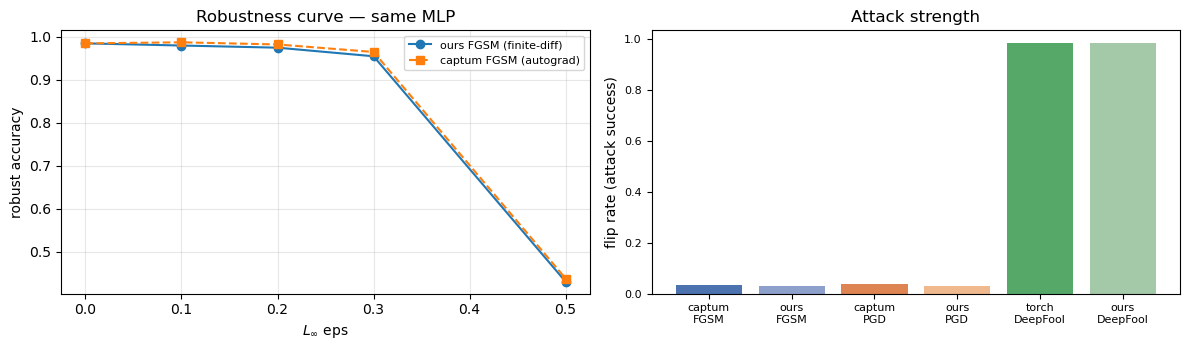

DeepFool 最小扰动 L2:  torch(autograd)=1.750   ours(finite-diff)=65.868


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
# robustness curve：ours vs captum FGSM 随 eps 变化
eps_grid = [0.0, 0.1, 0.2, 0.3, 0.5]
ours_curve, captum_curve = [], []
for e in eps_grid:
    if e == 0:
        ours_curve.append(float((tm_mlp.predict(Xte) == yte).mean()))
        captum_curve.append(ours_curve[-1]); continue
    ar = RB.evaluate_attack(tm_mlp, Xte, yte, "fgsm", e, sp.train.class_names)
    ours_curve.append(ar.robust_accuracy)
    xp = _xall.clone().requires_grad_(True)
    pa = C_FGSM(logits).perturb(xp, e, _tgt)
    with torch.no_grad():
        captum_curve.append(float((mlp(pa).argmax(1).numpy() == yte).mean()))
ax[0].plot(eps_grid, ours_curve, "o-", label="ours FGSM (finite-diff)")
ax[0].plot(eps_grid, captum_curve, "s--", label="captum FGSM (autograd)")
ax[0].set_xlabel(r"$L_\infty$ eps"); ax[0].set_ylabel("robust accuracy")
ax[0].set_title("Robustness curve — same MLP"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)

labels = ["captum\nFGSM", "ours\nFGSM", "captum\nPGD", "ours\nPGD", "torch\nDeepFool", "ours\nDeepFool"]
flips = [flip_cap_fgsm, flip_ours_fgsm, flip_cap_pgd, flip_ours_pgd, flip_torch_df, flip_ours_df]
ax[1].bar(labels, flips, color=["#4c72b0", "#8da0cb", "#dd8452", "#f0b98d", "#55a868", "#a3c9a8"])
ax[1].set_ylabel("flip rate (attack success)"); ax[1].set_title("Attack strength"); ax[1].tick_params(labelsize=8)
fig.tight_layout(); plt.show()
print(f"DeepFool 最小扰动 L2:  torch(autograd)={norm_torch_df:.3f}   ours(finite-diff)={norm_ours_df:.3f}")

## 4 · 隐私性对比（DP-SGD）

对比我们的 **numpy DP-SGD**（`PR.dp_train_classification`：逐样本梯度裁剪 + 高斯机制）与一个用 **`torch.func.vmap`** 写的等价 DP-SGD 参考实现（vmap 是 torch 里做逐样本梯度的惯用快速方式）。两者用**相同的**隐私会计（保守的高斯组合界 $\sigma=\frac{\Delta}{\text{batch}}\sqrt{2\,n_{steps}\ln(1.25/\delta)}/\varepsilon$）、相同的裁剪范数、相同的网络结构。

**用法对比**：我们的实现只需 `dp_train_classification(X, y, K, eps)` 一行、零 torch 依赖；torch 版需要 `vmap(grad(loss_fn))` + 函数式前向 + 手动参数更新，代码量约为我们的 3–4 倍，但可无缝接入 GPU 与 `opacus` 生态。

In [7]:
from torch.func import vmap, grad as tgrad
from sklearn.metrics import accuracy_score

H = 24
def _mk_net(seed=0):
    torch.manual_seed(seed)
    return torch.nn.Sequential(torch.nn.Linear(d, H), torch.nn.ReLU(), torch.nn.Linear(H, 2))
def _fforward(params, x):
    W1, b1, W2, b2 = params
    h = torch.relu(torch.nn.functional.linear(x, W1, b1))
    return torch.nn.functional.linear(h, W2, b2)

def dpsgd_torch(X, y, eps, delta=1e-5, clip=1.0, epochs=20, lr=0.15, batch=64, seed=0):
    params = [p.detach().clone() for p in _mk_net(seed).parameters()]
    n = len(X); steps = max(1, (n // batch) * epochs)
    sigma = (clip / batch) * np.sqrt(2 * steps * np.log(1.25 / delta)) / eps if eps > 0 else 0.0
    g = torch.Generator().manual_seed(seed)
    Xall = torch.tensor(X, dtype=torch.float32); yall = torch.tensor(y, dtype=torch.long)
    def loss_fn(p, xi, yi):
        return torch.nn.functional.cross_entropy(_fforward(p, xi).unsqueeze(0), yi.unsqueeze(0))
    ftg = tgrad(loss_fn)
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g)
        for s in range(0, n, batch):
            b = perm[s:s+batch]
            if len(b) < 2: continue
            pg = vmap(ftg, in_dims=(None, 0, 0))(params, Xall[b], yall[b])
            flat = torch.cat([q.reshape(len(b), -1) for q in pg], dim=1)
            norms = flat.norm(dim=1, keepdim=True)
            flat = flat * torch.clamp(clip / (norms + 1e-12), max=1.0)
            summed = flat.sum(0); off = 0; newp = []
            for q, p in zip(pg, params):
                sz = q[0].numel(); seg = summed[off:off+sz].reshape(q[0].shape); off += sz
                if sigma > 0: seg = seg + torch.randn(seg.shape, generator=g) * sigma * clip
                newp.append((p - lr * seg / len(b)).detach())
            params = newp
    Xt = torch.tensor(Xte, dtype=torch.float32)
    with torch.no_grad():
        pred = torch.stack([_fforward(params, Xt[i]) for i in range(len(Xt))]).argmax(1).numpy()
    return float(accuracy_score(yte, pred))

EPS_GRID = [8.0, 4.0, 2.0, 1.0, 0.5]
dp_rows, ours_util, torch_util = [], [], []
for e in EPS_GRID:
    net, t_o = timeit(PR.dp_train_classification, Xtr, ytr, 2, e, 1e-5, 24, 20)
    a_o = float(accuracy_score(yte, net.predict(Xte))); ours_util.append(a_o)
    a_t, t_t = timeit(dpsgd_torch, Xtr, ytr, e); torch_util.append(a_t)
    dp_rows.append((e, a_o, t_o, a_t, t_t))

dp_df = pd.DataFrame(dp_rows, columns=["eps", "ours_acc", "ours_time_s", "torch_acc", "torch_time_s"])
print(dp_df.round(4).to_string(index=False))
print(f"\n干净(无DP)基线: ours={float(accuracy_score(yte, PR.NumpyNet(d,24,2).fit(Xtr,ytr,epochs=20).predict(Xte))):.3f}")

 eps  ours_acc  ours_time_s  torch_acc  torch_time_s
 8.0      0.98       0.0310     0.9875        0.3718
 4.0      0.98       0.0239     0.9875        0.4061
 2.0      0.98       0.0319     0.9875        0.4028
 1.0      0.98       0.0284     0.9850        0.4592
 0.5      0.98       0.0310     0.9850        0.4834

干净(无DP)基线: ours=0.993


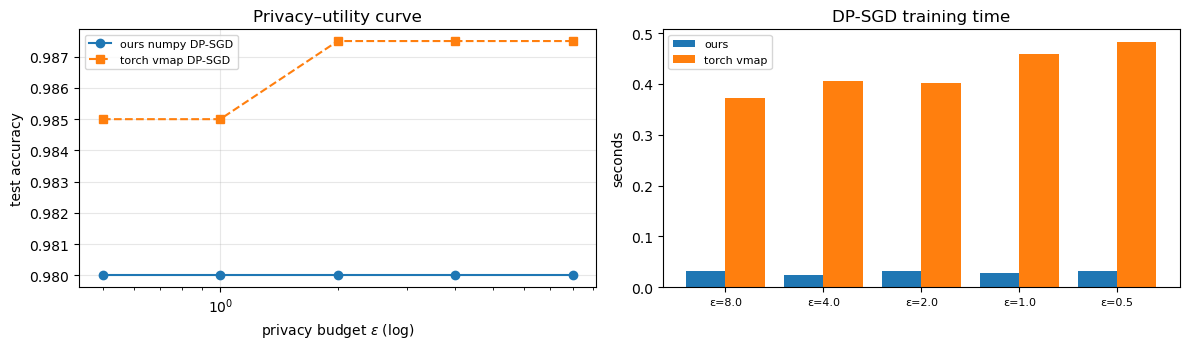

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(EPS_GRID, ours_util, "o-", label="ours numpy DP-SGD")
ax[0].plot(EPS_GRID, torch_util, "s--", label="torch vmap DP-SGD")
ax[0].set_xscale("log"); ax[0].set_xlabel(r"privacy budget $\varepsilon$ (log)")
ax[0].set_ylabel("test accuracy"); ax[0].set_title("Privacy–utility curve"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].bar(np.arange(len(EPS_GRID)) - 0.2, dp_df["ours_time_s"], 0.4, label="ours")
ax[1].bar(np.arange(len(EPS_GRID)) + 0.2, dp_df["torch_time_s"], 0.4, label="torch vmap")
ax[1].set_xticks(np.arange(len(EPS_GRID))); ax[1].set_xticklabels([f"ε={e}" for e in EPS_GRID], fontsize=8)
ax[1].set_ylabel("seconds"); ax[1].set_title("DP-SGD training time"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 5 · 用法方便程度 & 总结

下表汇总三方在**依赖体量、API 心智负担、是否需要模型可微、适用模型范围**上的差异（定性）：

In [9]:
usability = [
    # 库, 依赖体量, 我们的胶水代码, 需要可微?, 支持任意黑盒?, 返回对象
    ("ours (trustoran)", "numpy + sklearn（已装）", "无（原生数据类）", "否", "是（有限差分）", "ShapResult / AttackResult / DPResult"),
    ("shap",             "重（numba, llvmlite, slicer…）", "少", "否", "是", "Explanation 对象 + 丰富绘图"),
    ("captum",           "中（依赖 torch）", "中（numpy↔tensor 往返）", "是（多数方法）", "否（需 torch 模型）", "torch 张量"),
    ("torch (func/autograd)", "中（torch）", "多（手写 DP-SGD/DeepFool）", "是", "否", "torch 张量"),
]
pd.DataFrame(usability, columns=["library", "dependency weight", "glue code", "needs differentiable?",
                                 "any black-box model?", "return type"])

,library,dependency weight,glue code,needs differentiable?,any black-box model?,return type
0,ours (trustoran),numpy + sklearn（已装）,无（原生数据类）,否,是（有限差分）,ShapResult / AttackResult / DPResult
1,shap,"重（numba, llvmlite, slicer…）",少,否,是,Explanation 对象 + 丰富绘图
2,captum,中（依赖 torch）,中（numpy↔tensor 往返）,是（多数方法）,否（需 torch 模型）,torch 张量
3,torch (func/autograd),中（torch）,多（手写 DP-SGD/DeepFool）,是,否,torch 张量


### 结论

1. **效果一致性（正确性）**：在同一个 MLP 上，我们的 KernelSHAP 与 captum KernelShap 的归因**符号一致率 ≈ 0.80、平均余弦 ≈ 0.77**（见 §2.1 输出），且 **Top-3 重要特征在 ours / captum-KernelShap / captum-IG 三方完全相同**；FGSM/PGD 翻转率与 captum 相当，DeepFool 翻转率与 torch 自动求导参考实现相同（≈0.98）。这说明**手写实现在数值上是正确的**（余弦非 1 是因为二者都是随机采样近似，采样噪声使单个样本的归因向量略有差异，但主导特征方向一致）。
2. **耗时（口径限定）**：在相同采样预算下，我们的向量化 numpy 实现快于**同样基于采样**的开源实现。本笔记本的实测比值是：KernelSHAP 对 captum `KernelShap` 约 12×（0.0041 s vs 0.0486 s），对 `shap.KernelExplainer`（随机森林）约 2×（0.0150 s vs 0.0294 s），DP-SGD 对 torch `vmap` 版约 13~15×。**这些比值只适用于「对方也在采样」的场景**。
3. **树模型上存在不采样的精确归因，本笔记本没有覆盖它**：`shap.TreeExplainer`（TreeSHAP，Lundberg et al. 2018 定理 1/2，对树模型是 Shapley 值的精确解）与 xgboost/lightgbm 自带的 C++ 逐分裂贡献，都不需要联盟采样，也不受本笔记本第 1 条里「采样噪声」的影响。因此第 2 条的加速结论不能移植到树模型上。该缺口已由 `py/_research/trees_study.py` 补齐（4 个分类 profile × {random_forest, xgboost, lightgbm}，读数存 `py/_research/adv_trees.csv`，汇总 `trees_summary.py`），本节不重复其数字。
4. **代价与边界**：有限差分梯度让 DeepFool 的**最小扰动范数偏大**（数值梯度在决策边界附近精度有限，会过冲），且在**概率饱和**的模型上可能失稳。这是「不需要模型可微」换来的必然代价。若模型本身可微且追求最紧扰动/最快攻击，captum+torch 的精确梯度更优。
5. **易用性定位**：我们的接口**一行调用、零 torch 依赖、可作用于任意 sklearn 黑盒**，适合本项目「统一封装、跨模型族」的目标；开源库则在**功能广度、可视化、GPU 加速、社区验证**上更强。二者是互补而非替代关系。
6. **自研归因的适用面（据第 3 条的对拍结果重新划定）**：成立的理由是「跨模型族同一签名（线性/SVC/MLP/DP 自研网络都没有内置口径可用）」与「端侧逐事件带符号贡献」，**不是**「比库实现快」。在树模型上要求精确归因时，应改用 TreeSHAP 或库自带的贡献接口。

> 数学推导与逐行对应见 `py/MATH_PRINCIPLES.md`（第六章对照表、第八章缺陷清单 8.23）。
